# Choose smoothness and shrink unnecessary terms

A smooth needs enough basis functions to represent the relationship, but it also needs a penalty to avoid fitting noise. These are separate choices.

We will simulate a simple effect, a more irregular effect, and an irrelevant predictor. The example compares limited basis capacity, stronger smoothing, and penalties that can shrink an entire term toward zero.

## Generate two effects and an irrelevant predictor

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng = np.random.default_rng(102)
data = pd.DataFrame(rng.uniform(0, 1, (700, 3)), columns=["x", "z", "noise"])
functions = {"x": lambda x: np.sin(2*np.pi*x), "z": lambda z: .6*np.sin(8*np.pi*z), "noise": lambda x: np.zeros_like(x)}
data["y"] = functions["x"](data.x) + functions["z"](data.z) + rng.normal(0, .3, len(data))
train, test = train_test_split(data, test_size=.25, random_state=102)
models = {}

## Fit a basis that is too small

With four basis functions, the irregular z effect cannot express its repeated oscillations, regardless of the selected penalty.

In [2]:
models["Small basis"] = GAM(formula="y ~ s(x, bs='cr', k=4) + s(z, bs='cr', k=4) + s(noise, bs='cr', k=4)", smoothing_method="reml", optimize_smoothing=True).fit(train)

## Increase the basis dimension

Raising k enlarges the function space. REML still controls roughness within that space. The basis diagnostic is evidence to inspect, rather than an automatic acceptance rule.

In [3]:
formula = "y ~ s(x, bs='cr', k=18) + s(z, bs='cr', k=18) + s(noise, bs='cr', k=18)"
models["Estimated smoothness"] = GAM(formula=formula, smoothing_method="reml", optimize_smoothing=True).fit(train)
basis_results = pd.concat({name: model.k_check(n_rep=40, seed=102) for name, model in models.items()}, names=["Model", "Term"])
basis_results.round(3)

k_prime     edf  k_index  p_value
Model                Term                                       
Small basis          s(x)            3   2.994    1.031    0.750
                     s(z)            3   2.878    0.361    0.000
                     s(noise)        3   1.705    1.022    0.675
Estimated smoothness s(x)           17   9.418    1.043    0.875
                     s(z)           17  16.087    1.090    1.000
                     s(noise)       17   1.438    0.965    0.200

## Compare fixed and estimated smoothing

Fixed penalties are illustrative choices declared before test evaluation. Their values are not optimized against test outcomes.

In [4]:
models["Fixed weak penalty"] = GAM(formula=formula, smoothing_method="fixed", smoothing_params=[.001]*3).fit(train)
models["Fixed strong penalty"] = GAM(formula=formula, smoothing_method="fixed", smoothing_params=[100]*3).fit(train)

## Penalize unnecessary terms

An ordinary roughness penalty can leave an unpenalized component of a smooth. Increasing its penalty therefore need not remove the term entirely. Shrinkage bases and additional null-space penalties allow the whole effect to be penalized.

The shrinkage basis and `select=True` are separate models here.

In [5]:
models["Shrinkage basis"] = GAM(formula=formula.replace("'cr'", "'cs'"), smoothing_method="reml", optimize_smoothing=True).fit(train)
models["Additional selection penalty"] = GAM(formula=formula, select=True, smoothing_method="reml", optimize_smoothing=True).fit(train)
rows = []
for name, model in models.items():
    result = model.fit_result()
    rows.append({"Model": name, "Test RMSE": mean_squared_error(test.y, model.predict(test))**.5,
                 "Total EDF": result.edf_total, "Smoothing parameters": np.array2string(np.asarray(result.smoothing_params), precision=3)})
pd.DataFrame(rows).style.hide(axis="index").format({"Test RMSE": "{:.3f}", "Total EDF": "{:.2f}"})

Model,Test RMSE,Total EDF,Smoothing parameters
Small basis,0.527,8.58,[2.662e-01 5.992e+00 2.783e+02]
Estimated smoothness,0.320,27.94,[8.482e+01 1.894e+00 2.173e+05]
Fixed weak penalty,0.322,52.00,[0.001 0.001 0.001]
Fixed strong penalty,0.362,28.48,[100. 100. 100.]
Shrinkage basis,0.320,26.68,[9.488e+01 2.028e+00 2.409e+06]
Additional selection penalty,0.321,27.25,[8.469e+01 1.998e-02 1.895e+00 8.300e-01 2.292e+05 4.273e+01]


## Compare effect recovery and prediction

The dashed curves are centered using the training inputs, matching the fitted contribution reference. The irrelevant predictor has a true contribution of zero. Test RMSE compares all fits on a common scale; raw GCV and REML criteria are not ranked against one another.

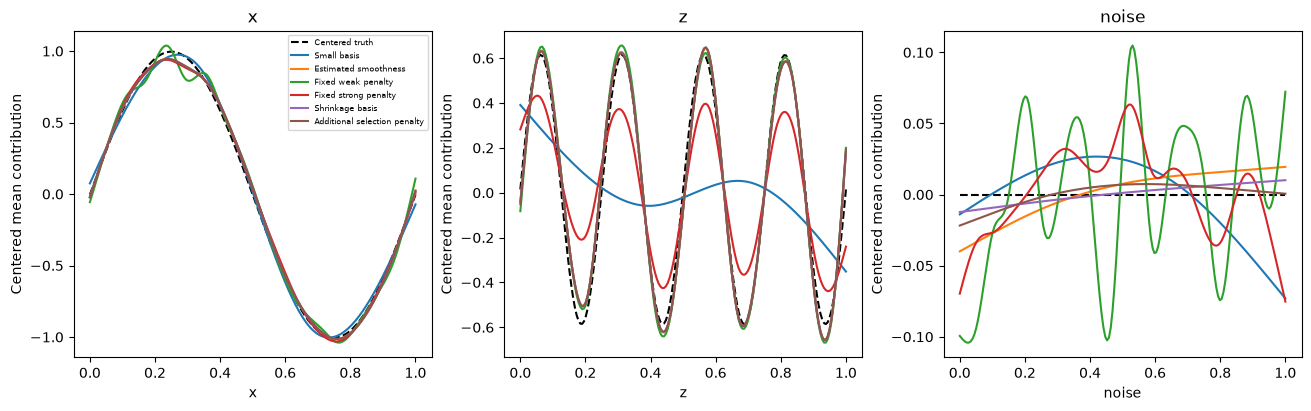

In [6]:
figure, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
values = np.linspace(0, 1, 180)
for axis, feature in zip(axes, functions):
    grid = pd.DataFrame({name: np.full(len(values), train[name].median()) for name in functions})
    grid[feature] = values
    axis.plot(values, functions[feature](values) - functions[feature](train[feature]).mean(), "k--", label="Centered truth")
    for name, model in models.items():
        result = model.fit_result()
        terms = np.asarray(model.predict(grid, type="terms"))
        reference_terms = np.asarray(model.predict(train, type="terms"))
        columns = [i for i, term in enumerate(result.term_results) if term.label.startswith(f"s({feature},")]
        effect = (terms[:, columns] - reference_terms[:, columns].mean(axis=0)).sum(axis=1)
        axis.plot(values, effect, label=name)
    axis.set(title=feature, xlabel=feature, ylabel="Centered mean contribution")
axes[0].legend(fontsize=6)
plt.show()
plt.close(figure)

The small basis misses the oscillating z effect: its k diagnostic has index 0.36 and simulated p-value 0 in this run. Increasing capacity lowers test RMSE from 0.527 to 0.320. Weak fixed penalties retain more wiggles in the irrelevant feature; shrinkage and selection penalties reduce that effect without materially improving test RMSE.